# Selenium WebDriver – Basic Commands (Python)

This notebook walks through the core Selenium 4 commands. Each section has a short explanation followed by a runnable example.

**How to use it**
- Run the cells **top to bottom**. Cell 2 opens a Chrome window and the `driver` stays open between cells, so you can watch each command happen.
- The last section closes the browser with `driver.quit()`.

**Practice sites used** (built for automation practice):
- https://www.selenium.dev/selenium/web/web-form.html
- https://www.selenium.dev/selenium/web/mouse_interaction.html
- https://the-internet.herokuapp.com

**Requirements:** Python 3.8+ and Google Chrome. Firefox or Edge also work if you change one line in the setup cell.

## 1. Install Selenium

Since Selenium **4.6**, **Selenium Manager** downloads the matching browser driver (for example chromedriver) automatically, so you don't need to install it yourself.

In [ ]:
# %pip install --upgrade selenium

Note: you may need to restart the kernel to use updated packages.


## 2. Imports and starting the browser

| Import | Used for |
|---|---|
| `webdriver` | Starting a browser (`webdriver.Chrome()`, `Firefox()`, `Edge()`) |
| `By` | Choosing how to locate elements |
| `Keys` | Special keys such as ENTER, TAB, and arrow keys |
| `WebDriverWait`, `expected_conditions` | Waiting for elements or conditions |
| `Select` | Working with `<select>` dropdowns |
| `ActionChains` | Mouse and keyboard actions (hover, drag, right-click) |

In [1]:
from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.common.keys import Keys
from selenium.webdriver.common.action_chains import ActionChains
from selenium.webdriver.support.ui import WebDriverWait, Select
from selenium.webdriver.support import expected_conditions as EC
from selenium.common.exceptions import NoSuchElementException, TimeoutException

In [ ]:
# options = webdriver.EdgeOptions()
# options.add_argument("--headless=new")
# driver = webdriver.Edge(options=options)
driver = webdriver.Firefox()          # or webdriver.Firefox() / webdriver.Chrome()

wait = WebDriverWait(driver, 10)   # reusable explicit wait, up to 10 seconds

print(driver.capabilities["browserName"], driver.capabilities["browserVersion"])

MicrosoftEdge 155.0.4283.45


> **Headless mode** (no visible window, useful on servers and in CI):
> ```python
> options = webdriver.ChromeOptions()
> options.add_argument("--headless=new")
> driver = webdriver.Chrome(options=options)
> ```

## 3. Browser navigation and window commands

| Command | What it does |
|---|---|
| `driver.get(url)` | Opens a URL and waits for the page to load |
| `driver.back()` / `driver.forward()` | Browser Back and Forward buttons |
| `driver.refresh()` | Reloads the page |
| `driver.title` | Page title |
| `driver.current_url` | Current URL |
| `driver.page_source` | Full HTML of the page |
| `driver.maximize_window()` | Maximizes the window |
| `driver.set_window_size(w, h)` / `get_window_size()` | Sets or reads the window size |

In [4]:
driver.get("https://www.boxofficemojo.com/")
print("Title:", driver.title)
print("URL:  ", driver.current_url)

Title: Home - Box Office Mojo
URL:   https://www.boxofficemojo.com/


In [ ]:
driver.get("https://www.selenium.dev/documentation/")
print("Now on:", driver.title)

Now on: The Selenium Browser Automation Project | Selenium


In [6]:
driver.back()
print("After back():   ", driver.title)

After back():    Home - Box Office Mojo


In [7]:
driver.forward()
print("After forward():", driver.title)

After forward(): The Selenium Browser Automation Project | Selenium


In [10]:
driver.refresh()
print("Page source length:", len(driver.page_source), "characters")

Page source length: 107754 characters


In [ ]:
driver.set_window_size(1024, 768)
print("Window size:", driver.get_window_size())

In [ ]:
driver.maximize_window()
print("Maximized:  ", driver.get_window_size())

## 4. Finding elements (locators)

- `driver.find_element(By.X, "value")` returns the **first** match and raises `NoSuchElementException` if nothing matches.
- `driver.find_elements(By.X, "value")` returns a **list** of every match, or an empty list `[]` if nothing matches.

| Locator | Example | Notes |
|---|---|---|
| `By.ID` | `(By.ID, "my-text-id")` | Fastest and most reliable |
| `By.NAME` | `(By.NAME, "my-textarea")` | Common on form fields |
| `By.CLASS_NAME` | `(By.CLASS_NAME, "form-control")` | Only **one** class name |
| `By.TAG_NAME` | `(By.TAG_NAME, "h1")` | |
| `By.LINK_TEXT` | `(By.LINK_TEXT, "Return to index")` | Exact text of an `<a>` link |
| `By.PARTIAL_LINK_TEXT` | `(By.PARTIAL_LINK_TEXT, "Return")` | Part of the link text |
| `By.CSS_SELECTOR` | `(By.CSS_SELECTOR, "button[type='submit']")` | Flexible and fast |
| `By.XPATH` | `(By.XPATH, "//select[@name='my-select']")` | Can match by text or move up the DOM |

**Rule of thumb:** use ID first, then NAME, then CSS selectors. Use XPath when nothing else works.

In [3]:
driver.get("https://www.selenium.dev/selenium/web/web-form.html")

In [27]:
by_id = driver.find_element(By.ID, "my-text-id")
print("ID ->", by_id.tag_name," , ", by_id.get_attribute("myprop"))

ID -> input  ,  myvalue


In [28]:
by_name = driver.find_element(By.NAME, "my-textarea")
print("NAME ->", by_name.tag_name)

NAME -> textarea


In [29]:
by_tag = driver.find_element(By.TAG_NAME, "h1")
print("TAG ->", by_tag.text)

TAG -> Web form


In [4]:
by_css = driver.find_element(By.CSS_SELECTOR, "button[type='submit']")
print("CSS ->", by_css.text)

CSS -> Submit


In [31]:
by_xpath = driver.find_element(By.XPATH, "//select[@name='my-select']")
print("XPATH ->", by_xpath.tag_name)

XPATH -> select


In [34]:
by_link  = driver.find_element(By.LINK_TEXT, "Return to index")
print("LINK ->", by_link.text)

LINK -> Return to index


In [32]:
by_link  = driver.find_element(By.PARTIAL_LINK_TEXT, "Return")
print("LINK ->", by_link.text)

LINK -> Return to index


In [35]:
by_class = driver.find_elements(By.CLASS_NAME, "form-control")   # note: find_elementS
for i in by_class:
    print(i.tag_name)
print("CLASS ->", len(by_class), "elements with class 'form-control'")

input
input
textarea
input
input
input
input
input
input
CLASS -> 9 elements with class 'form-control'


In [36]:
# find_elements returns an empty list when nothing matches
print("find_elements:", driver.find_elements(By.ID, "does-not-exist"))

# find_element raises an exception when nothing matches
try:
    driver.find_element(By.ID, "does-not-exist")
except NoSuchElementException:
    print("find_element: NoSuchElementException raised")

find_elements: []
find_element: NoSuchElementException raised


In [37]:
# You can also search INSIDE an element (scoped search)
form = driver.find_element(By.TAG_NAME, "form")
inputs_in_form = form.find_elements(By.TAG_NAME, "input")
print(len(inputs_in_form), "<input> elements inside the form")

14 <input> elements inside the form


## 5. Interacting with elements

| Command | What it does |
|---|---|
| `el.click()` | Clicks the element |
| `el.send_keys("text")` | Types into the element |
| `el.clear()` | Clears an input or textarea |
| `el.submit()` | Submits the form the element belongs to |
| `el.text` | Visible text |
| `el.get_attribute("value")` | Any attribute or property value |
| `el.is_displayed()` | Visible on the page? |
| `el.is_enabled()` | Enabled (not disabled)? |
| `el.is_selected()` | Checked? (checkboxes and radio buttons) |

In [48]:
text_input = driver.find_element(By.ID, "my-text-id")
text_input.clear()
text_input.send_keys("Hello Selenium")
print("Text input value:", text_input.get_attribute("value"))

Text input value: Hello Selenium


In [56]:
textarea = driver.find_element(By.NAME, "my-textarea")
textarea.clear()
textarea.send_keys("Line one",Keys.ENTER , "Line two")
print("Textarea value: ", repr(textarea.get_attribute("value")),sep='') # repr

Textarea value: 'Line one\nLine two'


In [67]:
# Checkboxes
check2 = driver.find_element(By.ID, "my-check-2")
print("Checkbox 2 selected before click:", check2.is_selected())
check2.click()
print("Checkbox 2 selected after click: ", check2.is_selected())

Checkbox 2 selected before click: True
Checkbox 2 selected after click:  False


In [72]:
# radio
radio2 = driver.find_element(By.ID, "my-radio-2")
radio2.click()
print("Radio 2 selected:", radio2.is_selected())

Radio 2 selected: True


In [83]:
# State checks
disabled = driver.find_element(By.NAME, "my-disabled")
print("Disabled input is_enabled():   ", disabled.is_enabled())
print("Disabled input is_displayed(): ", disabled.is_displayed())

Disabled input is_enabled():    False
Disabled input is_displayed():  False


In [84]:
# Reading information about an element
heading = driver.find_element(By.TAG_NAME, "h1")
print("tag_name: ", heading.tag_name)
print("text:     ", heading.text)
print("size:     ", heading.size)
print("location: ", heading.location)
print("font-size:", heading.value_of_css_property("font-size"))

tag_name:  h1
text:      Web form
size:      {'height': 34, 'width': 376}
location:  {'x': 12, 'y': 0}
font-size: 28px


## 6. Dropdowns (`<select>`)

Wrap the `<select>` element in `Select(...)`, then choose an option in one of three ways:

| Command | Picks the option by |
|---|---|
| `select_by_visible_text("Two")` | The text the user sees |
| `select_by_value("3")` | Its `value="..."` attribute |
| `select_by_index(1)` | Position (starting at 0) |

In [87]:
dropdown = Select(driver.find_element(By.NAME, "my-select"))

for option in dropdown.options:
    print("text ",option.text," | value ",option.get_attribute("value"))

text  Open this select menu  | value  Open this select menu
text  One  | value  1
text  Two  | value  2
text  Three  | value  3


In [88]:
dropdown.select_by_visible_text("Two")
print("By text  ->", dropdown.first_selected_option.text)

By text  -> Two


In [89]:
dropdown.select_by_value("3")
print("By value ->", dropdown.first_selected_option.text)

By value -> Three


In [ ]:
dropdown.select_by_index(1)
print("By index ->", dropdown.first_selected_option.text)

By index -> One


## 7. Submitting a form

Click the submit button, then **wait** for the result page before reading it. Waits are covered in section 9.

In [ ]:
driver.find_element(By.CSS_SELECTOR, "button[type='submit']").click()

message = wait.until(EC.visibility_of_element_located((By.ID, "message")))
print("Page title:", driver.title)
print("Message:   ", message.text)

Page title: Web form - target page


## 8. Keyboard keys

Pass any `Keys.*` constant to `send_keys()`. You can mix keys and text in one call, for example `send_keys("hello", Keys.ENTER)`.

Common keys: `ENTER`, `TAB`, `ESCAPE`, `BACK_SPACE`, `DELETE`, `SPACE`, `ARROW_UP/DOWN/LEFT/RIGHT`, `CONTROL`, `SHIFT`, `F1`–`F12`.

In [5]:
driver.get("https://the-internet.herokuapp.com/key_presses")
box = driver.find_element(By.ID, "target")

for key in [Keys.SPACE, Keys.ARROW_UP, Keys.ESCAPE, "z"]:
    box.send_keys(key)
    print(driver.find_element(By.ID, "result").text)

You entered: SPACE
You entered: UP
You entered: ESCAPE
You entered: Z


In [111]:
print(driver.find_element(By.ID, "result").text)

You entered: Z


In [112]:
# Keyboard shortcuts: hold CONTROL and press "a" to select all, then delete
box.clear()
box.send_keys("some text")

In [113]:
box.send_keys(Keys.CONTROL, "a")   # use Keys.COMMAND on macOS

In [114]:
box.send_keys(Keys.BACK_SPACE)

In [115]:
print("Value after Ctrl+A, Backspace:", repr(box.get_attribute("value")))

Value after Ctrl+A, Backspace: ''


## 9. Waits (very important)

Pages and elements load at different speeds. If your script looks for an element before it exists, it fails. There are three ways to deal with this:

| Approach | How | Verdict |
|---|---|---|
| `time.sleep(5)` | Always waits the full 5 seconds | ❌ Slow and still breaks easily |
| **Implicit wait** | `driver.implicitly_wait(5)`: every `find_element` retries for up to 5 seconds | ⚠️ OK for simple scripts |
| **Explicit wait** | `WebDriverWait(driver, 10).until(condition)` waits for a *specific* condition | ✅ Recommended |

Don't use implicit and explicit waits together, because the timeouts can combine in unpredictable ways.

**Common `expected_conditions` (EC):**
- `presence_of_element_located`
- `visibility_of_element_located`
- `element_to_be_clickable`
- `invisibility_of_element_located`
- `text_to_be_present_in_element`
- `title_contains`
- `url_contains`
- `alert_is_present`
- `number_of_windows_to_be`
- `frame_to_be_available_and_switch_to_it`

In [6]:
# This page shows "Hello World!" only after a loading bar finishes
driver.get("https://the-internet.herokuapp.com/dynamic_loading/1")
driver.find_element(By.CSS_SELECTOR, "#start button").click()

finish = wait.until(EC.visibility_of_element_located((By.ID, "finish")))
print("Appeared:", finish.text)

Appeared: Hello World!


In [7]:
# element_to_be_clickable returns the element, so you can click it right away
driver.get("https://the-internet.herokuapp.com/dynamic_loading/2")
wait.until(EC.element_to_be_clickable((By.CSS_SELECTOR, "#start button"))).click()
print(wait.until(EC.visibility_of_element_located((By.ID, "finish"))).text)

Hello World!


In [8]:
# When the condition never becomes true, you get a TimeoutException
try:
    WebDriverWait(driver, 2).until(EC.title_contains("This will never match"))
except TimeoutException:
    print("TimeoutException after 2 seconds")

TimeoutException after 2 seconds


## 10. JavaScript alerts, confirms and prompts

Switch to the popup with `driver.switch_to.alert`, or wait for it with `EC.alert_is_present()`.

| Command | What it does |
|---|---|
| `alert.text` | Reads the popup message |
| `alert.accept()` | Clicks **OK** |
| `alert.dismiss()` | Clicks **Cancel** |
| `alert.send_keys("...")` | Types into a prompt popup |

In [9]:
driver.get("https://the-internet.herokuapp.com/javascript_alerts")
result = lambda: driver.find_element(By.ID, "result").text

In [10]:
# 1) Simple alert
driver.find_element(By.XPATH, "//button[text()='Click for JS Alert']").click()
alert = wait.until(EC.alert_is_present())
print("Alert text:", alert.text)
alert.accept()
print("  ->", result())

Alert text: I am a JS Alert
  -> You successfully clicked an alert


In [11]:
# 2) Confirm: click Cancel
driver.find_element(By.XPATH, "//button[text()='Click for JS Confirm']").click()
alert = wait.until(EC.alert_is_present())
alert.dismiss()
print("Confirm    ->", result())

Confirm    -> You clicked: Cancel


In [12]:
# 3) Prompt: type text, then OK
driver.find_element(By.XPATH, "//button[text()='Click for JS Prompt']").click()
alert = wait.until(EC.alert_is_present())
alert.send_keys("Selenium rocks")
alert.accept()
print("Prompt     ->", result())

Prompt     -> You entered: Selenium rocks


## 11. Frames (`<frame>` / `<iframe>`)

Elements inside a frame are **invisible** to Selenium until you switch into that frame.

| Command | What it does |
|---|---|
| `driver.switch_to.frame(name_or_id_or_index_or_element)` | Enters a frame |
| `driver.switch_to.parent_frame()` | Goes up one level |
| `driver.switch_to.default_content()` | Goes back to the main page |

In [13]:
driver.get("https://the-internet.herokuapp.com/nested_frames")

In [14]:
driver.switch_to.frame("frame-top")        # enter the top frameset
driver.switch_to.frame("frame-left")       # enter the left frame inside it
print(driver.find_element(By.TAG_NAME, "body").text)

LEFT


In [15]:
driver.switch_to.parent_frame()            # back up to frame-top
driver.switch_to.frame("frame-middle")
print(driver.find_element(By.TAG_NAME, "body").text)

MIDDLE


In [16]:
driver.switch_to.default_content()         # back to the main page
driver.switch_to.frame("frame-bottom")
print(driver.find_element(By.TAG_NAME, "body").text)

driver.switch_to.default_content()         # always switch back when done

BOTTOM


## 12. Multiple windows and tabs

Each window or tab has a unique **handle** (an ID string).

| Command | What it does |
|---|---|
| `driver.current_window_handle` | Handle of the current window |
| `driver.window_handles` | List of all open handles |
| `driver.switch_to.window(handle)` | Switches to a window |
| `driver.switch_to.new_window("tab")` | Opens and switches to a new tab (`"window"` for a new window) |
| `driver.close()` | Closes **only** the current window |

In [62]:
driver.get("https://the-internet.herokuapp.com/windows")
original = driver.current_window_handle

In [63]:
# 1. Get the current window handles count
original_windows = driver.window_handles

# 2. Click the element that opens the new tab
driver.find_element(By.LINK_TEXT, "Click Here").click()

# 3. Wait until the number of windows is greater than before
wait.until(lambda d: len(d.window_handles) > len(original_windows))

True

In [67]:
for handle in driver.window_handles:
    if handle != original:
        driver.switch_to.window(handle)
        break

In [68]:
print("New tab heading:", driver.find_element(By.TAG_NAME, "h3").text)

New tab heading: New Window


In [69]:
driver.close()                       # close the new tab
driver.switch_to.window(original)    # you MUST switch back after close()
print("Back on:", driver.title)

Back on: The Internet


In [70]:
# Open your own new tab
driver.switch_to.new_window("tab")

In [71]:
driver.get("https://www.selenium.dev")
print("New tab title:", driver.title, "| open tabs:", len(driver.window_handles))

New tab title: Selenium | open tabs: 2


In [72]:
driver.close()
driver.switch_to.window(original)

## 13. Mouse actions (`ActionChains`)

Build a chain of actions, then run it with `.perform()`.

| Command | What it does |
|---|---|
| `move_to_element(el)` | Hovers over the element |
| `double_click(el)` | Double-clicks |
| `context_click(el)` | Right-clicks |
| `drag_and_drop(src, target)` | Drags one element onto another |
| `click_and_hold(el)` / `release()` | Low-level press and release |
| `key_down(Keys.SHIFT)` / `key_up(...)` | Holds a modifier key while doing other actions |

In [73]:
driver.get("https://www.selenium.dev/selenium/web/mouse_interaction.html")

In [84]:
clickable = driver.find_element(By.ID, "clickable")
ActionChains(driver).double_click(clickable).perform()
print("double_click  ->", driver.find_element(By.ID, "click-status").text)

double_click  -> double-clicked


In [78]:
hoverable = driver.find_element(By.ID, "hover")
ActionChains(driver).move_to_element(hoverable).perform()
print("move_to_element ->", driver.find_element(By.ID, "move-status").text)

move_to_element -> hovered


In [81]:
draggable = driver.find_element(By.ID, "draggable")
droppable = driver.find_element(By.ID, "droppable")
ActionChains(driver).drag_and_drop(draggable, droppable).perform()
print("drag_and_drop ->", driver.find_element(By.ID, "drop-status").text)

drag_and_drop -> dropped


In [85]:
ActionChains(driver).context_click(clickable).perform()
print("context_click ->", driver.find_element(By.ID, "click-status").text)

context_click -> context-clicked


## 14. JavaScript, scrolling and screenshots

| Command | What it does |
|---|---|
| `driver.execute_script("js code")` | Runs JavaScript; use `return` to get a value back |
| `driver.execute_script("...arguments[0]...", el)` | Passes elements or values into the script |
| `driver.save_screenshot("file.png")` | Screenshot of the browser viewport |
| `el.screenshot("file.png")` | Screenshot of one element |

In [95]:
driver.get("https://the-internet.herokuapp.com/large")

In [96]:
# Scroll to the bottom, then read the scroll position
driver.execute_script("window.scrollTo(0, document.body.scrollHeight);")
print("Scrolled to Y =", driver.execute_script("return window.pageYOffset;"))

Scrolled to Y = 3253.5087890625


In [97]:
# Scroll a specific element into view
heading = driver.find_element(By.TAG_NAME, "h3")
driver.execute_script("arguments[0].scrollIntoView();", heading)
print("Scrolled back to Y =", driver.execute_script("return window.pageYOffset;"))

Scrolled back to Y = 28.070175170898438


In [98]:
# Get values from the page with JavaScript
print("Title via JS:", driver.execute_script("return document.title;"))

Title via JS: The Internet


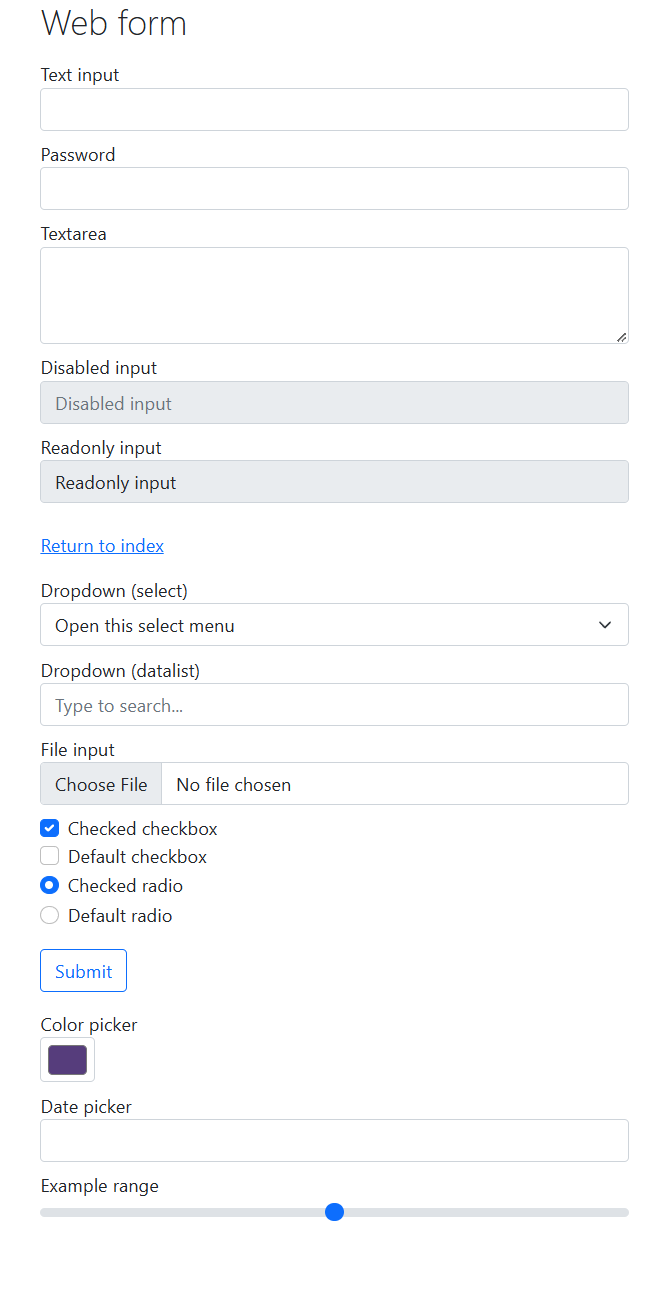

In [102]:
from IPython.display import Image, display

driver.get("https://www.selenium.dev/selenium/web/web-form.html")
driver.save_screenshot("data/page.png")
driver.find_element(By.TAG_NAME, "form").screenshot("data/form.png")

display(Image("data/page.png", width=1000))

## 15. Cookies

Cookies apply to the domain of the page that is **currently open**.

In [105]:
driver.add_cookie({"name": "demo_cookie", "value": "12345"})
print("One cookie:", driver.get_cookie("demo_cookie"))
print("All cookie names:", [c["name"] for c in driver.get_cookies()])

driver.delete_cookie("demo_cookie")
driver.delete_all_cookies()
print("After delete_all_cookies:", driver.get_cookies())

One cookie: {'domain': 'www.selenium.dev', 'httpOnly': False, 'name': 'demo_cookie', 'path': '/', 'sameSite': 'Lax', 'secure': True, 'value': '12345'}
All cookie names: ['demo_cookie']
After delete_all_cookies: []


## 16. Closing the browser

| Command | What it does |
|---|---|
| `driver.close()` | Closes the **current** tab or window. The session keeps running if other tabs are open. |
| `driver.quit()` | Closes **all** windows and ends the WebDriver session. **Always** call this at the end. |

In [106]:
driver.quit()
print("Browser closed.")

Browser closed.


## 18. Cheat sheet

| Task | Command |
|---|---|
| Start browser | `driver = webdriver.Chrome()` |
| Open URL | `driver.get(url)` |
| Title / URL | `driver.title`, `driver.current_url` |
| Back / Forward / Refresh | `driver.back()`, `driver.forward()`, `driver.refresh()` |
| Find one / many | `find_element(By.ID, "x")`, `find_elements(By.CSS_SELECTOR, ".x")` |
| Click / Type / Clear | `el.click()`, `el.send_keys("txt")`, `el.clear()` |
| Read text / attribute | `el.text`, `el.get_attribute("href")` |
| State | `el.is_displayed()`, `el.is_enabled()`, `el.is_selected()` |
| Dropdown | `Select(el).select_by_visible_text("A")` |
| Wait | `WebDriverWait(driver, 10).until(EC.visibility_of_element_located((By.ID, "x")))` |
| Alert | `driver.switch_to.alert.accept()` / `.dismiss()` |
| Frame | `driver.switch_to.frame("name")`, `driver.switch_to.default_content()` |
| Window / tab | `driver.switch_to.window(handle)`, `driver.switch_to.new_window("tab")` |
| Hover / Drag | `ActionChains(driver).move_to_element(el).perform()` |
| Run JavaScript | `driver.execute_script("return document.title;")` |
| Screenshot | `driver.save_screenshot("x.png")` |
| End session | `driver.quit()` |